# DRCD CPU 小試驗（真實生成；預設離線 replay）
固定公開 DRCD test 的重劃 8 題 development / 24 題 held-out experiment test，另 1 題 warmup。不是官方 split，也不聲稱模型未見訓練。

只允許本機 CPU / 付費硬上限 0。`DRCD_MODE=fresh` 才下載與生成，預設 replay 只讀本次保存輸出。核心資料、抽樣、評分、派工、HTTP 與圖表均在以下原生 cells。

DRCD: DRCKnowledgeTeam, CC-BY-SA 3.0; upstream b944790de5af02c5fbb7cd9cb1473d27d169eebf。TCEval-v2 僅作分發來源，不替整套資料宣稱同一授權。兩個 Qwen2.5 Instruct GGUF 為 Qwen 官方 Apache-2.0 模型。

In [1]:
import collections, hashlib, unicodedata

def normalize(text):
    # 本實驗自訂：NFKC + casefold，移除 Unicode 標點與空白；不繁簡轉換。
    return ''.join(c for c in unicodedata.normalize('NFKC', text).casefold()
                   if not c.isspace() and not unicodedata.category(c).startswith('P'))

def score(prediction, golds, error=None):
    p = normalize(prediction or '')
    if error or not p or not golds:
        return 0.0, 0.0
    em, f1 = 0.0, 0.0
    for gold in golds:
        g = normalize(gold)
        em = max(em, float(p == g))
        common = sum((collections.Counter(p) & collections.Counter(g)).values())
        f1 = max(f1, 2 * common / (len(p) + len(g)) if g else 0.0)
    return em, f1


In [2]:
SYSTEM = '請只根據提供的段落回答問題。僅輸出最短的答案原文，不要解釋或加入前綴。'

def messages(row):
    return [{'role': 'system', 'content': SYSTEM},
            {'role': 'user', 'content': '段落：' + row['paragraph'] + '\n問題：' + row['question']}]

def small_ids(rows, share):
    # 只使用公開 ID，不讀 references / 分數 / 測試標籤；兩個 split 都整除 grid。
    assert 0 <= share <= 1 and float(len(rows) * share).is_integer()
    ordered = sorted((r['id'] for r in rows),
                     key=lambda i: hashlib.sha256(('route-v1:' + str(i)).encode()).hexdigest())
    return set(ordered[:int(len(rows) * share)])


## 固定協議（看結果之前）
- seed=20261106；先依原段落 SHA256 分組，sorted groups → seeded sample 33 groups → 每組 seeded 選 1 題。前 8 dev、中 24 test、末 1 warmup。
- small-model share grid = 0, 0.25, 0.5, 0.75, 1。固定 ID hash 排序精確分配。僅 dev 模擬各配置，選 EM/F1 均不低於全 1.5B 且估計耗時最短者，平手優先較低 small share；先落盤 decision 再生成 test。
- test 三方案都重新發送 24 次請求，非事後加權；兩個 server 全程同駐、逐題串行。每題 120 秒完整 request 硬期限（獨立 process watchdog；另有 socket 讀取 timeout）、64 output tokens、temperature=0、固定 seed；不重試。
- normalized EM / 字元 multiset F1 是本實驗自訂，非 DRCD 官方 tokenizer；多 gold 各取最大值，空輸出/錯誤均 0。不用 LLM judge。
- 正式推論（含 warmup）20 分鐘，整體 fresh 35 分鐘，超時由獨立 process watchdog 寫 partial/failure 後 SIGKILL 已驗證的專用 kernel process group（含 servers）；整體期限涵蓋 setup 到最後 audit，不能在阻塞 I/O 中延長。cell exception / parentdeath 同樣清理。無 GPU、無付費 API。


In [3]:
# Infrastructure only: fixed Python source, no shell, no model-generated commands.
import os, sys, json, time, subprocess, signal
from pathlib import Path

WATCHDOG_SOURCE = r'''
import os, sys, json, time, signal
from pathlib import Path
out = Path(sys.argv[1]); pid = int(sys.argv[2]); identity = sys.argv[3]
def stat():
    try: return Path(f'/proc/{pid}/stat').read_text().split(') ')[1].split()
    except FileNotFoundError: return None
def write(name, obj):
    p = out / name; t = p.with_suffix('.watchdog.tmp')
    with t.open('w') as f:
        json.dump(obj, f, indent=2); f.flush(); os.fsync(f.fileno())
    t.replace(p)
s = stat()
if not s or s[19] != identity or int(s[2]) != pid or os.getpgrp() == pid:
    sys.exit(91)
write('watchdog-ready.json', {'pid': os.getpid(), 'target_pid': pid, 'target_pgid': pid})
while True:
    reason = None
    s = stat()
    if not s or s[0] == 'Z': reason = 'parentdeath'
    elif s[19] != identity: sys.exit(92)  # never signal a reused PID
    try:
        state = json.loads((out / 'watchdog-control.json').read_text())
        now = time.monotonic()
        for key in ['overall', 'inference', 'request']:
            if state.get(key) is not None and now >= state[key]:
                reason = key + ' hard deadline'; break
        if state.get('abort'): reason = 'exception: ' + state['abort']
        if state.get('done') and not reason:
            write('watchdog.json', {'status':'complete', 'target_pid':pid, 'elapsed_seconds':now-state['started']})
            sys.exit(0)
    except Exception as exc:
        state = {}; reason = 'watchdog control failure: ' + repr(exc)
    if reason:
        evidence = {'status':'partial', 'reason':reason, 'target_pid':pid,
                    'target_pgid':pid, 'request':state.get('active_request'), 'monotonic':time.monotonic()}
        try:
            raw = out / 'raw-generations.jsonl'
            evidence['requests_saved'] = len(raw.read_text().splitlines()) if raw.exists() else 0
            write('failure.json', evidence); write('watchdog.json', evidence)
        finally:
            # Disk/evidence errors must never prevent the deadline's kill.
            # Only the group verified above as this dedicated worker/kernel's own group.
            try: os.killpg(pid, signal.SIGKILL)
            except ProcessLookupError: pass
        sys.exit(0)
    time.sleep(.02)
'''

class ResourceGuard:
    def __init__(self, out, overall_seconds=2100):
        self.pid = os.getpid()
        if os.getpgrp() != self.pid or os.getsid(0) != self.pid:
            raise RuntimeError('fresh requires a dedicated kernel session with PGID == PID; refusing to signal shared group')
        self.out = Path(out); self.out.mkdir(parents=True, exist_ok=True)
        identity = Path(f'/proc/{self.pid}/stat').read_text().split(') ')[1].split()[19]
        now = time.monotonic()
        self.state = dict(started=now, overall=now+overall_seconds, inference=None, request=None, done=False)
        self._write()
        ready = self.out / 'watchdog-ready.json'
        ready.unlink(missing_ok=True)
        self.proc = subprocess.Popen([sys.executable, '-c', WATCHDOG_SOURCE, str(self.out), str(self.pid), identity], start_new_session=True)
        until = time.monotonic()+5
        while not ready.exists():
            if self.proc.poll() is not None or time.monotonic() > until:
                raise RuntimeError('independent watchdog failed startup')
            time.sleep(.01)
    def _write(self):
        p = self.out / 'watchdog-control.json'; t = p.with_suffix('.kernel.tmp')
        with t.open('w') as f:
            json.dump(self.state, f); f.flush(); os.fsync(f.fileno())
        t.replace(p)
    def inference(self, seconds=1200):
        self.state['inference'] = time.monotonic()+seconds; self._write()
    def request(self, seconds=120, metadata=None):
        self.state['request'] = time.monotonic()+seconds
        self.state['active_request'] = metadata; self._write()
    def clear_request(self):
        self.state['request'] = None; self.state['active_request'] = None; self._write()
    def inference_complete(self):
        self.state['inference'] = None; self._write()
    def abort(self, error):
        self.state['abort'] = str(error); self._write()
    def finish(self):
        self.state['done'] = True; self._write()
        self.proc.wait(timeout=5)
        assert self.proc.returncode == 0
        assert json.loads((self.out/'watchdog.json').read_text())['status'] == 'complete'


In [4]:
import os, sys, json, time, random, platform, subprocess, tarfile, socket
from pathlib import Path
from urllib.request import urlopen, Request
from concurrent.futures import ThreadPoolExecutor

MODE = os.environ.get('DRCD_MODE', 'replay')
assert MODE in {'replay', 'fresh'}
ROOT = Path.cwd()
OUT = ROOT / 'results' / 'drcd-cpu'
CACHE = Path.home() / '.cache/llm-cost-frontier/drcd-cpu'
START = time.monotonic()
TOTAL_DEADLINE = START + 35 * 60
SEED = 20261106
DATA_REV = '93ae26a94572907f6d33f9844abd9d074bcc3723'
DATA_URL = f'https://huggingface.co/datasets/MediaTek-Research/TCEval-v2/resolve/{DATA_REV}/drcd/test-00000-of-00001.parquet'
MODELS = {
 'small': {'repo': 'Qwen/Qwen2.5-0.5B-Instruct-GGUF', 'revision': '9217f5db79a29953eb74d5343926648285ec7e67', 'file': 'qwen2.5-0.5b-instruct-q4_k_m.gguf'},
 'large': {'repo': 'Qwen/Qwen2.5-1.5B-Instruct-GGUF', 'revision': '91cad51170dc346986eccefdc2dd33a9da36ead9', 'file': 'qwen2.5-1.5b-instruct-q4_k_m.gguf'},
}
BINARY_URL = 'https://github.com/ggml-org/llama.cpp/releases/download/b12110/llama-b12110-bin-ubuntu-x64.tar.gz'
BINARY_SHA = '368227edcc229be5f9bed16a2223d79b5e41d0ac2e19bcf5825e82291c060e55'

def save(name, value):
    OUT.mkdir(parents=True, exist_ok=True)
    dest = OUT / name
    temp = dest.with_suffix(dest.suffix + '.tmp')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n')
    temp.replace(dest)

def file_sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def fetch_json(url, timeout=30):
    with urlopen(url, timeout=timeout) as response:
        return json.load(response)

def download(url, destination, expected=None):
    if not expected or len(expected) != 64:
        raise ValueError('download requires expected SHA256 from pinned official metadata')
    if destination.exists() and (not expected or file_sha(destination) == expected):
        return file_sha(destination)
    part = destination.with_suffix(destination.suffix + '.part')
    with urlopen(url, timeout=60) as response, open(part, 'wb') as f:
        while chunk := response.read(4 * 1024 * 1024):
            if time.monotonic() > TOTAL_DEADLINE:
                raise TimeoutError('35-minute overall hard deadline')
            f.write(chunk)
    digest = file_sha(part)
    if expected and digest != expected:
        raise ValueError(f'SHA256 mismatch: {destination.name} {digest} != {expected}')
    part.replace(destination)
    return digest

guard = None
if MODE == 'fresh':
    if (OUT / 'raw-generations.jsonl').exists():
        raise FileExistsError('Archive existing results before fresh; refusing to overwrite')
    guard = ResourceGuard(OUT, overall_seconds=max(.001, TOTAL_DEADLINE-time.monotonic()))
    TOTAL_DEADLINE = guard.state['overall']
    def abort_on_cell_error(result):
        error = result.error_before_exec or result.error_in_exec
        if error is not None:
            guard.abort(f'{type(error).__name__}: {error}')
        elif globals().get('guard_ready_to_finish', False):
            # Called only after the last audit cell body has successfully completed.
            guard.finish()
            get_ipython().events.unregister('post_run_cell', abort_on_cell_error)
    get_ipython().events.register('post_run_cell', abort_on_cell_error)

print('mode:', MODE, '; paid budget: 0; GPU: disabled')


mode: replay ; paid budget: 0; GPU: disabled


In [5]:
# Fresh only: pinned download, integrity, native parquet sampling.
if MODE == 'fresh':
    import pyarrow.parquet as pq
    CACHE.mkdir(parents=True, exist_ok=True)
    OUT.mkdir(parents=True, exist_ok=True)
    if (OUT / 'raw-generations.jsonl').exists():
        raise FileExistsError('Archive existing results/drcd-cpu before a fresh run; never append across runs')
    save('protocol.json', {'seed': SEED, 'dev': 8, 'test': 24, 'warmup': 1,
         'shares': [0, .25, .5, .75, 1], 'max_tokens': 64, 'temperature': 0,
         'per_request_timeout_seconds': 120, 'inference_deadline_seconds': 1200,
         'overall_deadline_seconds': 2100, 'paid_budget': 0, 'gpu_layers': 0,
         'system_prompt': SYSTEM, 'dataset_revision': DATA_REV,
         'sampling': 'sorted paragraph SHA256 groups; random.Random(seed).sample 33; choice one row per group'})
    for model in MODELS.values():
        meta_url = f"https://huggingface.co/api/models/{model['repo']}/revision/{model['revision']}?blobs=true"
        meta = fetch_json(meta_url)
        assert meta['sha'] == model['revision'] and not meta.get('gated')
        item = next(x for x in meta['siblings'] if x['rfilename'] == model['file'])
        model['sha256'] = item['lfs']['sha256']
        model['size'] = item['lfs']['size']
        model['url'] = f"https://huggingface.co/{model['repo']}/resolve/{model['revision']}/{model['file']}"
        save(model['file'] + '.metadata.json', meta)
    dataset_meta = fetch_json(f'https://huggingface.co/api/datasets/MediaTek-Research/TCEval-v2/revision/{DATA_REV}?blobs=true')
    assert dataset_meta['sha'] == DATA_REV
    dataset_item = next(x for x in dataset_meta['siblings'] if x['rfilename'] == 'drcd/test-00000-of-00001.parquet')
    dataset_sha = dataset_item['lfs']['sha256']
    assert dataset_sha == 'c96bd232753f77096a05fa16e58904018495ae3fefd062216042600818666364'
    save('dataset.metadata.json', dataset_meta)
    tasks = [(DATA_URL, CACHE / 'drcd-test.parquet', dataset_sha),
             (BINARY_URL, CACHE / 'llama-b12110.tar.gz', BINARY_SHA)]
    tasks += [(m['url'], CACHE / m['file'], m['sha256']) for m in MODELS.values()]
    with ThreadPoolExecutor(max_workers=4) as pool:
        hashes = list(pool.map(lambda t: download(*t), tasks))
    binary_dir = CACHE / 'llama-b12110'
    binary_dir.mkdir(exist_ok=True)
    with tarfile.open(CACHE / 'llama-b12110.tar.gz') as archive:
        archive.extractall(binary_dir, filter='data')
    SERVER = next(binary_dir.rglob('llama-server'))
    # Inspect actual supported options, not a guessed command.
    help_result = subprocess.run([str(SERVER), '--help'], capture_output=True, text=True, timeout=30)
    (OUT / 'llama-server-help.txt').write_text(help_result.stdout + help_result.stderr)
    if help_result.returncode:
        raise RuntimeError(help_result.stderr)
    for required in ['--host', '--port', '--threads', '--parallel', '--n-gpu-layers', '--device']:
        assert required in help_result.stdout, required
    rows = pq.read_table(CACHE / 'drcd-test.parquet').to_pylist()
    assert len(rows) == 3493
    groups = collections.defaultdict(list)
    for idx, row in enumerate(rows):
        h = hashlib.sha256(row['paragraph'].encode('utf-8')).hexdigest()
        groups[h].append((idx, row))
    rng = random.Random(SEED)
    selected = []
    for h in rng.sample(sorted(groups), 33):
        idx, original = rng.choice(groups[h])
        selected.append(dict(original, source_row=idx, context_sha256=h))
    dev, test, warmup = selected[:8], selected[8:32], selected[32:]
    assert len({r['context_sha256'] for r in selected}) == 33
    assert len({r['id'] for r in selected}) == 33
    manifest = {'dataset': 'MediaTek-Research/TCEval-v2', 'revision': DATA_REV,
                'config': 'drcd', 'source_split': 'test', 'source_url': DATA_URL,
                'source_sha256': hashes[0], 'source_rows': len(rows),
                'paragraph_groups': len(groups), 'seed': SEED,
                'notice': 'Experimental resplit of public historical test, not official development/test and not guaranteed unseen training data',
                'dev': dev, 'test': test, 'warmup': warmup}
    save('sample-manifest.json', manifest)
    save('assets.json', {'models': MODELS, 'binary_url': BINARY_URL, 'binary_sha256': BINARY_SHA,
                        'dataset_sha256': hashes[0], 'server_path': str(SERVER)})
    save('environment.json', {'python': sys.version, 'platform': platform.platform(),
         'cpu': subprocess.check_output(['lscpu'], text=True),
         'packages': subprocess.check_output([sys.executable, '-m', 'pip', 'list'], text=True) if False else
              {n: __import__('importlib.metadata', fromlist=['version']).version(n) for n in ['pyarrow','nbclient','nbformat','ipykernel','matplotlib']},
         'gpu': False, 'paid_api_calls': 0})
    print('Downloaded, verified, sampled:', len(dev), len(test), len(warmup))
else:
    manifest = json.loads((OUT / 'sample-manifest.json').read_text())
    dev, test, warmup = (manifest[k] for k in ['dev', 'test', 'warmup'])
    print('Replay frozen manifest:', len(dev), len(test), len(warmup))


Replay frozen manifest: 8 24 1


In [6]:
# The metrics helper also powers replay; no model calls here.
def aggregate(records):
    n = len(records)
    return {'n': n, 'em': sum(r['em'] for r in records) / n if n else 0,
            'f1': sum(r['f1'] for r in records) / n if n else 0,
            'elapsed_seconds': sum(r['elapsed_seconds'] for r in records),
            'prompt_tokens': sum(r.get('usage', {}).get('prompt_tokens', 0) for r in records),
            'completion_tokens': sum(r.get('usage', {}).get('completion_tokens', 0) for r in records),
            'errors': sum(bool(r.get('error')) for r in records)}


In [7]:
# All model requests and dispatch are native to this cell. Finally always stops servers.
if MODE == 'fresh':
    records, processes, logs, commands, lifecycle = [], {}, {}, {}, {}
    inference_start = None
    deadline = TOTAL_DEADLINE
    stop_reason = None

    def request_model(row, model, phase, scheme):
        if time.monotonic() >= deadline:
            raise TimeoutError('Formal inference/overall hard deadline reached')
        payload = {'model': model, 'messages': messages(row), 'max_tokens': 64,
                   'temperature': 0, 'seed': SEED, 'stream': False, 'cache_prompt': False}
        started = time.monotonic()
        record = {'order': len(records), 'id': row['id'], 'context_sha256': row['context_sha256'],
                  'phase': phase, 'scheme': scheme, 'model': model, 'request': payload,
                  'started_monotonic': started, 'attempt': 1, 'retry': False,
                  'output': '', 'finish_reason': None, 'usage': {}, 'error': None}
        guard.request(120, {k: record[k] for k in ['order','id','phase','scheme','model']})
        try:
            req = Request(f"http://127.0.0.1:{lifecycle[model]['port']}/v1/chat/completions",
                          data=json.dumps(payload, ensure_ascii=False).encode(),
                          headers={'Content-Type': 'application/json'})
            with urlopen(req, timeout=min(120, max(.01, deadline - time.monotonic()))) as response:
                raw = json.load(response)
            record['response'] = raw
            record['output'] = raw['choices'][0]['message'].get('content') or ''
            record['finish_reason'] = raw['choices'][0].get('finish_reason')
            record['usage'] = raw.get('usage', {})
        except Exception as exc:
            record['error'] = f'{type(exc).__name__}: {exc}'
        record['elapsed_seconds'] = time.monotonic() - started
        record['em'], record['f1'] = score(record['output'], row['references'], record['error'])
        records.append(record)
        with open(OUT / 'raw-generations.jsonl', 'a') as f:
            f.write(json.dumps(record, ensure_ascii=False) + '\n')
            f.flush()
            os.fsync(f.fileno())
        save('progress.json', {'requests': len(records), 'last': {k: record[k] for k in ['order','phase','scheme','id','model','error']},
                              'elapsed_seconds': time.monotonic() - START, 'paid_api_calls': 0})
        guard.clear_request()
        print(phase, scheme, len(records), model, record['elapsed_seconds'], flush=True)
        return record

    try:
        for name, model in MODELS.items():
            with socket.socket() as s:
                s.bind(('127.0.0.1', 0))
                port = s.getsockname()[1]
            command = [str(SERVER), '--model', str(CACHE / model['file']),
                       '--host', '127.0.0.1', '--port', str(port),
                       '--threads', '4', '--threads-batch', '4', '--parallel', '1',
                       '--ctx-size', '8192', '--n-gpu-layers', '0', '--device', 'none']
            commands[name] = command
            save('commands.json', commands)
            logs[name] = open(OUT / f'server-{name}.log', 'w')
            ts = time.monotonic()
            env = dict(os.environ, CUDA_VISIBLE_DEVICES='', HIP_VISIBLE_DEVICES='', ROCR_VISIBLE_DEVICES='')
            proc = subprocess.Popen(command, stdout=logs[name], stderr=subprocess.STDOUT, env=env)
            processes[name] = proc
            lifecycle[name] = {'port': port, 'pid': proc.pid, 'startup_start_monotonic': ts}
        for name, proc in processes.items():
            while True:
                if proc.poll() is not None:
                    raise RuntimeError(f'{name} server exited {proc.returncode}; see server log')
                if time.monotonic() >= min(TOTAL_DEADLINE, lifecycle[name]['startup_start_monotonic'] + 120):
                    raise TimeoutError(f'{name} server startup timeout')
                try:
                    health = fetch_json(f"http://127.0.0.1:{lifecycle[name]['port']}/health", timeout=1)
                    if health.get('status') == 'ok':
                        break
                except Exception:
                    time.sleep(.2)
            lifecycle[name]['startup_seconds'] = time.monotonic() - lifecycle[name]['startup_start_monotonic']
        guard.inference(20*60)
        inference_start = time.monotonic()
        deadline = min(TOTAL_DEADLINE, inference_start + 20 * 60)
        for name in MODELS:
            request_model(warmup[0], name, 'warmup', 'warmup')
        # Predeclared interleaving limits pure all-small/all-large temporal blocks on dev.
        dev_records = {}
        for index, row in enumerate(dev):
            for name in (['small','large'] if index % 2 == 0 else ['large','small']):
                r = request_model(row, name, 'dev', 'collect')
                dev_records[(row['id'], name)] = r
        baseline = aggregate([dev_records[(r['id'], 'large')] for r in dev])
        grid = []
        for share in [0, .25, .5, .75, 1]:
            ids = small_ids(dev, share)
            metrics = aggregate([dev_records[(r['id'], 'small' if r['id'] in ids else 'large')] for r in dev])
            grid.append(dict(small_share=share, eligible=metrics['em'] >= baseline['em'] and metrics['f1'] >= baseline['f1'], **metrics))
        chosen = min((g for g in grid if g['eligible']), key=lambda g: (g['elapsed_seconds'], g['small_share']))
        decision = {'small_share': chosen['small_share'], 'grid': grid, 'baseline': baseline,
                    'selected_on': 'dev only', 'frozen_before_test': True,
                    'frozen_at_monotonic': time.monotonic(),
                    'test_routes': {r['id']: ('small' if r['id'] in small_ids(test, chosen['small_share']) else 'large') for r in test}}
        save('decision.json', decision)
        decision_sha = file_sha(OUT / 'decision.json')
        save('decision-sha256.json', {'sha256': decision_sha, 'first_test_order': len(records)})
        # True dispatch: each scheme gets a new local inference call; rotate scheme order by item.
        schemes = ['all_large', 'all_small', 'frozen_mix']
        for index, row in enumerate(test):
            sequence = schemes[index % 3:] + schemes[:index % 3]
            for scheme in sequence:
                name = {'all_large': 'large', 'all_small': 'small',
                        'frozen_mix': decision['test_routes'][row['id']]}[scheme]
                request_model(row, name, 'test', scheme)
        assert file_sha(OUT / 'decision.json') == decision_sha
    except BaseException as exc:
        stop_reason = f'{type(exc).__name__}: {exc}'
        save('failure.json', {'error': stop_reason, 'requests_saved': len(records)})
        print('PARTIAL:', stop_reason)
        raise
    finally:
        for name, proc in processes.items():
            if proc.poll() is None:
                proc.terminate()
                try:
                    proc.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    proc.kill()
                    proc.wait(timeout=10)
            lifecycle[name]['exit_code'] = proc.returncode
            lifecycle[name]['stopped_verified'] = proc.poll() is not None
            try:
                with socket.create_connection(('127.0.0.1', lifecycle[name]['port']), timeout=.2):
                    lifecycle[name]['port_closed_verified'] = False
            except OSError:
                lifecycle[name]['port_closed_verified'] = True
        for log in logs.values():
            log.close()
        save('lifecycle.json', lifecycle)
        summary = {'complete': stop_reason is None and len(records) == 90, 'stop_reason': stop_reason,
                   'paid_api_calls': 0, 'local_model_requests': len(records),
                   'local_model_requests_by_phase': dict(collections.Counter(r['phase'] for r in records)),
                   'gpu_allocations': 0, 'collection_elapsed_seconds': time.monotonic() - START,
                   'inference_elapsed_seconds': time.monotonic() - inference_start if inference_start else None,
                   'warmup': aggregate([r for r in records if r['phase'] == 'warmup']),
                   'dev_collection': aggregate([r for r in records if r['phase'] == 'dev']),
                   'test': {s: aggregate([r for r in records if r['phase'] == 'test' and r['scheme'] == s])
                            for s in ['all_large','all_small','frozen_mix']},
                   'notes': 'Single CPU pilot; warm cache and temporal effects. Per-scheme request elapsed excludes startup/warmup/dev. No dollar-savings or statistical-generalization claim.'}
        save('summary.json', summary)
        print(json.dumps(summary, ensure_ascii=False, indent=2))
    guard.inference_complete()
else:
    records = [json.loads(line) for line in (OUT / 'raw-generations.jsonl').read_text().splitlines()]
    summary = json.loads((OUT / 'summary.json').read_text())
    decision = json.loads((OUT / 'decision.json').read_text()) if (OUT / 'decision.json').exists() else None
    assert len(records) == summary['local_model_requests']
    by_id = {r['id']: r for r in dev + test + warmup}
    for r in records:
        assert (r['em'], r['f1']) == score(r['output'], by_id[r['id']]['references'], r['error'])
        assert r['request']['messages'] == messages(by_id[r['id']])
    for scheme, metrics in summary['test'].items():
        assert metrics == aggregate([r for r in records if r['phase'] == 'test' and r['scheme'] == scheme])
    print(json.dumps(summary, ensure_ascii=False, indent=2))


{
  "complete": true,
  "stop_reason": null,
  "paid_api_calls": 0,
  "local_model_requests": 90,
  "local_model_requests_by_phase": {
    "warmup": 2,
    "dev": 16,
    "test": 72
  },
  "gpu_allocations": 0,
  "collection_elapsed_seconds": 191.83211490139365,
  "inference_elapsed_seconds": 187.90855085849762,
  "warmup": {
    "n": 2,
    "em": 0.5,
    "f1": 0.5909090909090909,
    "elapsed_seconds": 3.9053326221182942,
    "prompt_tokens": 796,
    "completion_tokens": 13,
    "errors": 0
  },
  "dev_collection": {
    "n": 16,
    "em": 0.625,
    "f1": 0.7178308823529411,
    "elapsed_seconds": 34.528029658831656,
    "prompt_tokens": 6942,
    "completion_tokens": 135,
    "errors": 0
  },
  "test": {
    "all_large": {
      "n": 24,
      "em": 0.625,
      "f1": 0.780787037037037,
      "elapsed_seconds": 63.23072106856853,
      "prompt_tokens": 9839,
      "completion_tokens": 118,
      "errors": 0
    },
    "all_small": {
      "n": 24,
      "em": 0.4583333333333333,
 

## 圖表：只讀已保存結果，不重新呼叫模型
EM/F1 使用 0–1 比例；時間是串行請求 wall time，不是美元或吞吐量保證。全部採集成本另列於 summary，避免只報方案時間而隱藏 development 和 warmup。


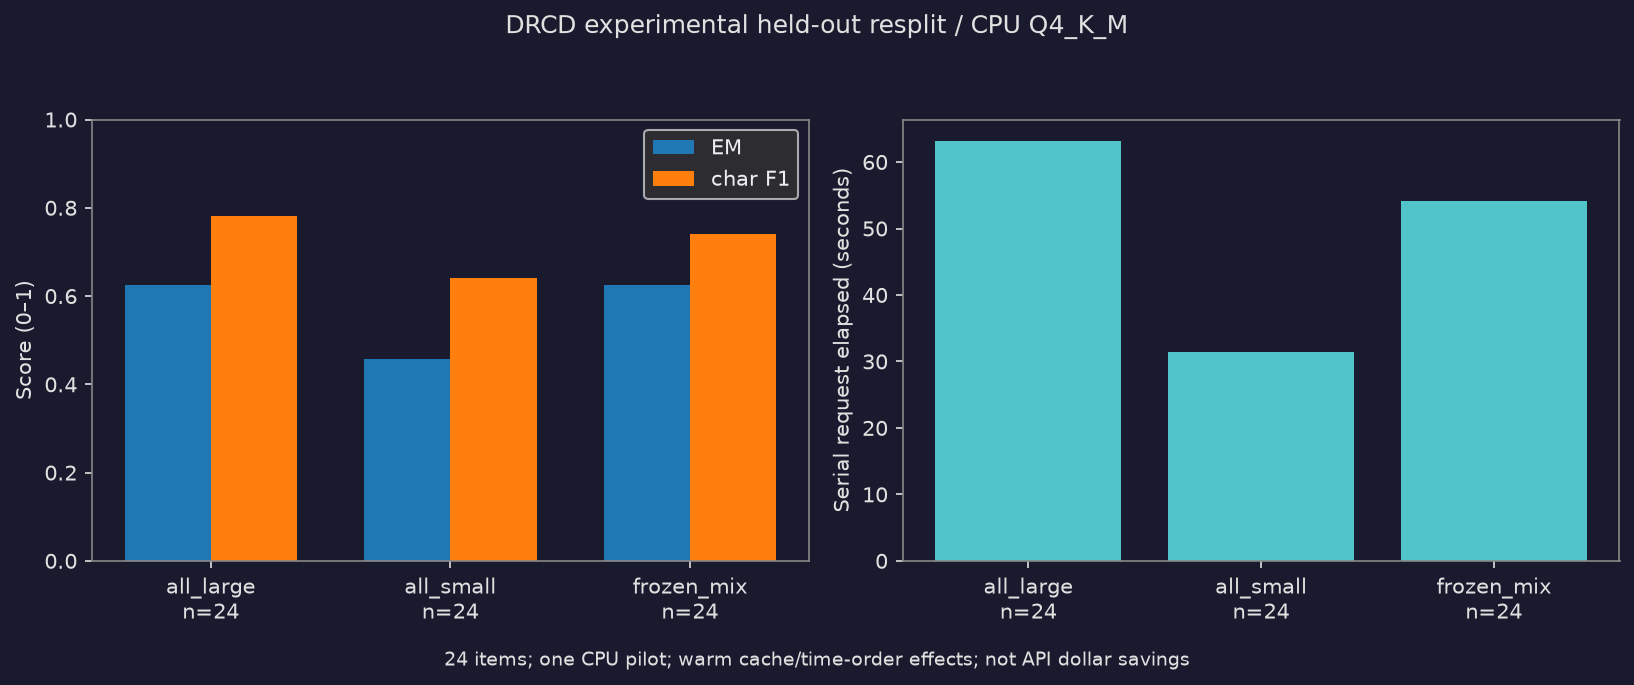

In [8]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
plt.rcParams.update({'figure.facecolor':'#1a1a2e', 'axes.facecolor':'#1a1a2e',
                     'text.color':'#e0e0e0', 'axes.labelcolor':'#e0e0e0',
                     'xtick.color':'#e0e0e0', 'ytick.color':'#e0e0e0', 'axes.edgecolor':'#888'})
labels = list(summary['test'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
x = list(range(len(labels)))
axes[0].bar([i-.18 for i in x], [summary['test'][s]['em'] for s in labels], width=.36, label='EM')
axes[0].bar([i+.18 for i in x], [summary['test'][s]['f1'] for s in labels], width=.36, label='char F1')
axes[0].set_ylim(0, 1)
axes[0].legend(facecolor='#333', labelcolor='#eee')
axes[0].set_ylabel('Score (0–1)')
axes[1].bar(x, [summary['test'][s]['elapsed_seconds'] for s in labels], color='#51c4ca')
axes[1].set_ylabel('Serial request elapsed (seconds)')
for ax in axes:
    ax.set_xticks(x, [f"{s}\nn={summary['test'][s]['n']}" for s in labels])
fig.suptitle('DRCD experimental held-out resplit / CPU Q4_K_M')
fig.text(.5, .015, '24 items; one CPU pilot; warm cache/time-order effects; not API dollar savings', ha='center', fontsize=9)
fig.tight_layout(rect=(0,.04,1,.94))
chart = OUT / 'comparison.png'
fig.savefig(chart, dpi=150, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(chart)))


In [9]:
# Replayable acceptance audit: recompute selection from dev raw records, not the summary.
assert len(dev) == 8 and len(test) == 24 and len(warmup) == 1
assert len({r['context_sha256'] for r in dev + test + warmup}) == 33
assert len(records) == summary['local_model_requests']
if summary['complete']:
    assert len(records) == 90
    assert [r['order'] for r in records] == list(range(90))
    assert collections.Counter(r['phase'] for r in records) == {'warmup': 2, 'dev': 16, 'test': 72}
    proof = json.loads((OUT / 'decision-sha256.json').read_text())
    assert file_sha(OUT / 'decision.json') == proof['sha256']
    assert proof['first_test_order'] == 18
    dev_map = {(r['id'], r['model']): r for r in records if r['phase'] == 'dev'}
    recomputed_grid = []
    baseline = aggregate([dev_map[(r['id'], 'large')] for r in dev])
    for share in [0, .25, .5, .75, 1]:
        assigned = small_ids(dev, share)
        m = aggregate([dev_map[(r['id'], 'small' if r['id'] in assigned else 'large')] for r in dev])
        recomputed_grid.append(dict(small_share=share, eligible=m['em'] >= baseline['em'] and m['f1'] >= baseline['f1'], **m))
    assert recomputed_grid == decision['grid']
    selected = min([g for g in recomputed_grid if g['eligible']], key=lambda g:(g['elapsed_seconds'],g['small_share']))
    assert selected['small_share'] == decision['small_share']
    for row in test:
        rs = [r for r in records if r['phase'] == 'test' and r['id'] == row['id']]
        assert {r['scheme'] for r in rs} == {'all_large','all_small','frozen_mix'} and len(rs) == 3
        assert all(r['started_monotonic'] >= decision['frozen_at_monotonic'] for r in rs)
    for r in records:
        assert r['request']['messages'] == messages(next(row for row in dev + test + warmup if row['id'] == r['id']))
        assert r['request']['max_tokens'] == 64 and r['request']['temperature'] == 0 and r['request']['seed'] == SEED
    life = json.loads((OUT / 'lifecycle.json').read_text())
    assert all(x['stopped_verified'] and x['port_closed_verified'] for x in life.values())
    audit = {'complete': True, 'requests': len(records), 'paid_api_calls': 0,
             'all_source_context_hashes_match': all(hashlib.sha256(r['paragraph'].encode()).hexdigest() == r['context_sha256'] for r in dev + test + warmup),
             'dev_only_selection_recomputed': True, 'decision_hash_matches': True,
             'test_request_counts': dict(collections.Counter(r['scheme'] for r in records if r['phase'] == 'test')),
             'test_mix_model_counts': dict(collections.Counter(r['model'] for r in records if r['scheme'] == 'frozen_mix')),
             'finish_reasons': dict(collections.Counter(r['finish_reason'] for r in records)),
             'all_requests_error_free': all(r['error'] is None for r in records),
             'saved_test_mix_matches_large_em': summary['test']['frozen_mix']['em'] >= summary['test']['all_large']['em'],
             'saved_test_mix_matches_large_f1': summary['test']['frozen_mix']['f1'] >= summary['test']['all_large']['f1'],
             'warning': 'Development equality does not guarantee held-out F1 equality; this run is not a demonstrated quality-preserving saving.'}
    assert audit['all_source_context_hashes_match']
    save('notebook-audit.json', audit)
    print(json.dumps(audit, ensure_ascii=False, indent=2))
if MODE == 'fresh':
    assert summary['complete'], 'partial fresh is not an accepted run'
    guard_ready_to_finish = True  # post_run_cell disarms only after this body completes


{
  "complete": true,
  "requests": 90,
  "paid_api_calls": 0,
  "all_source_context_hashes_match": true,
  "dev_only_selection_recomputed": true,
  "decision_hash_matches": true,
  "test_request_counts": {
    "all_large": 24,
    "all_small": 24,
    "frozen_mix": 24
  },
  "test_mix_model_counts": {
    "large": 18,
    "small": 6
  },
  "finish_reasons": {
    "stop": 90
  },
  "all_requests_error_free": true,
  "saved_test_mix_matches_large_em": true,
  "saved_test_mix_matches_large_f1": false,
  "warning": "Development equality does not guarantee held-out F1 equality; this run is not a demonstrated quality-preserving saving."
}
